<a href="https://colab.research.google.com/github/JuanitaRozo/Transformers/blob/main/Mecanismo_de_atenci%C3%B3n_aplicado_a_series_de_tiempo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, LSTM, Layer
)
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("TensorFlow:", tf.__version__)
print("Librerías cargadas correctamente")


TensorFlow: 2.21.0
Librerías cargadas correctamente


In [ ]:

np.random.seed(42)

tiempo = np.arange(0, 1500)

serie = (
    0.5 * np.sin(0.02 * tiempo) +
    0.3 * np.sin(0.05 * tiempo) +
    0.001 * tiempo +
    np.random.normal(0, 0.08, len(tiempo))
)

datos = pd.DataFrame({
    "Tiempo": tiempo,
    "Valor": serie
})

datos.head()


,Tiempo,Valor
0,0,0.039737
1,1,0.014932
2,2,0.103760
3,3,0.199656
4,4,0.084826


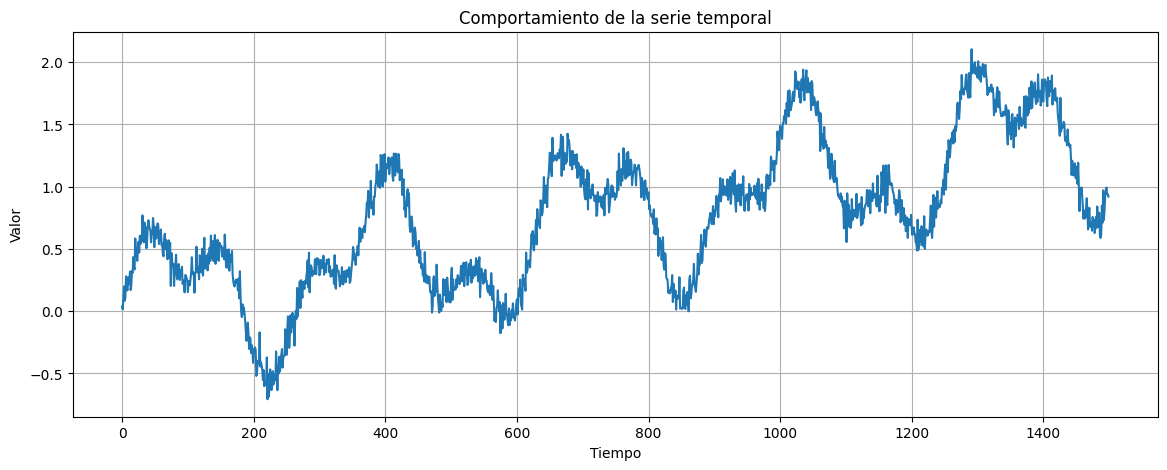

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(datos["Tiempo"], datos["Valor"])
plt.title("Comportamiento de la serie temporal")
plt.xlabel("Tiempo")
plt.ylabel("Valor")
plt.grid(True)

plt.show()


In [ ]:

scaler = MinMaxScaler(feature_range=(0, 1))

datos_normalizados = scaler.fit_transform(
    datos[["Valor"]]
)

print("Dimensiones:", datos_normalizados.shape)
print("Valor mínimo:", datos_normalizados.min())
print("Valor máximo:", datos_normalizados.max())


Dimensiones: (1500, 1)
Valor mínimo: 0.0
Valor máximo: 0.9999999999999999


In [ ]:

VENTANA = 30

def crear_secuencias(datos, ventana):
    X, y = [], []

    for i in range(len(datos) - ventana):
        X.append(datos[i:i + ventana])
        y.append(datos[i + ventana])

    return np.array(X), np.array(y)


X, y = crear_secuencias(datos_normalizados, VENTANA)

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Dimensiones de X: (1470, 30, 1)
Dimensiones de y: (1470, 1)


In [ ]:

limite = int(len(X) * 0.80)

X_train = X[:limite]
X_test = X[limite:]

y_train = y[:limite]
y_test = y[limite:]

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)


Datos de entrenamiento: (1176, 30, 1)
Datos de prueba: (294, 30, 1)


In [ ]:

class MecanismoAtencion(Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="pesos_atencion",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="sesgo_atencion",
            shape=(1,),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        puntuaciones = tf.nn.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        pesos = tf.nn.softmax(
            puntuaciones, axis=1
        )

        contexto = tf.reduce_sum(
            inputs * pesos,
            axis=1
        )

        return contexto


In [ ]:

entrada = Input(shape=(VENTANA, 1))

lstm = LSTM(64, return_sequences=True)(entrada)

atencion = MecanismoAtencion()(lstm)

capa_densa = Dense(32, activation="relu")(atencion)

salida = Dense(1)(capa_densa)

modelo_atencion = Model(
    inputs=entrada,
    outputs=salida
)

modelo_atencion.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

modelo_atencion.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mecanismo_atencion              │ (None, 64)             │            65 │
│ (MecanismoAtencion)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,074 (74.51 KB)

 Trainable params: 19,074 (74.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

historial_atencion = modelo_atencion.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)


Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0391 - mae: 0.1522 - val_loss: 0.0217 - val_mae: 0.1200
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0083 - mae: 0.0711 - val_loss: 0.0068 - val_mae: 0.0685
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0094 - mae: 0.0756 - val_loss: 0.0067 - val_mae: 0.0697
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0091 - mae: 0.0748 - val_loss: 0.0066 - val_mae: 0.0687
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0083 - mae: 0.0718 - val_loss: 0.0063 - val_mae: 0.0670
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0078 - mae: 0.0694 - val_loss: 0.0061 - val_mae: 0.0657
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0074 - mae: 0.0678 - val_loss: 0.0060 - val_mae: 0.0649
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0071 - mae: 0.0667 - val_loss: 0.0059 - val_mae: 0.0644
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.006

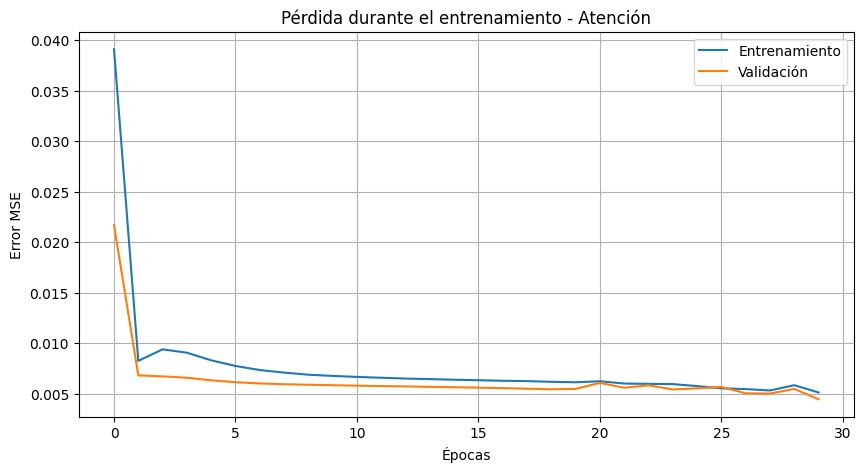

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    historial_atencion.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial_atencion.history["val_loss"],
    label="Validación"
)

plt.title("Pérdida durante el entrenamiento - Atención")
plt.xlabel("Épocas")
plt.ylabel("Error MSE")
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

perdida, mae = modelo_atencion.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Error MSE:", perdida)
print("Error MAE:", mae)


Error MSE: 0.006488383281975985
Error MAE: 0.0673387199640274


In [ ]:

predicciones = modelo_atencion.predict(X_test)

predicciones_reales = scaler.inverse_transform(predicciones)
valores_reales = scaler.inverse_transform(y_test)

mse = mean_squared_error(
    valores_reales,
    predicciones_reales
)

mae_real = mean_absolute_error(
    valores_reales,
    predicciones_reales
)

print("MSE:", mse)
print("MAE:", mae_real)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
MSE: 0.05127360420414137
MAE: 0.1892969239051644


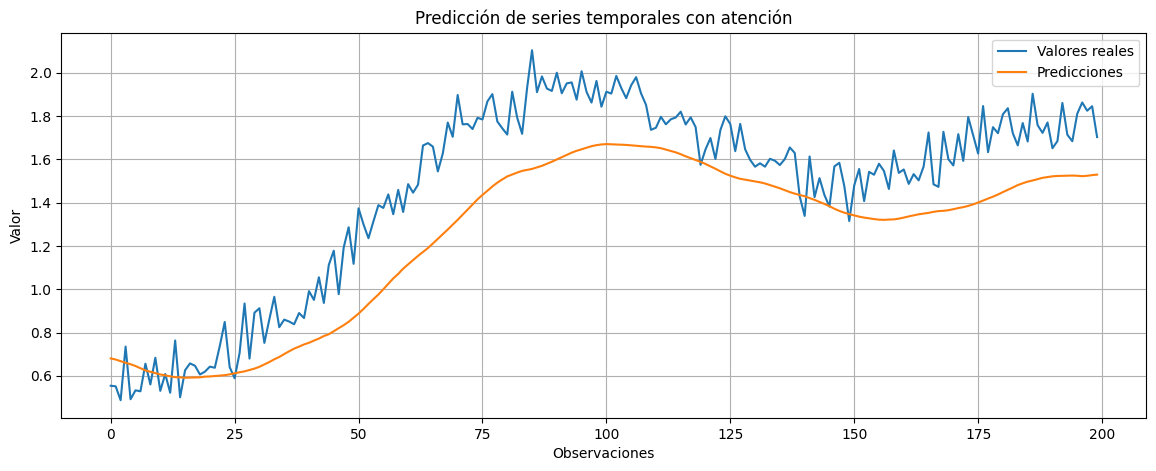

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(
    valores_reales[:200],
    label="Valores reales"
)

plt.plot(
    predicciones_reales[:200],
    label="Predicciones"
)

plt.title("Predicción de series temporales con atención")
plt.xlabel("Observaciones")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)

plt.show()


In [ ]:

modelo_atencion.save("modelo_atencion.keras")

print("Modelo guardado correctamente")


Modelo guardado correctamente
